# EN3150 Assignment 03 - Resource-Constrained CNN for Edge Image Classification

## Team Pixel Perfect

### Group Members
1. Dharmakeerthi P.K.G.C.L. — 230140J
2. Fernando L.T.J. — 230183R
3. Wijethilaka J.S. — 230730T
4. Arachchige M.A.D.T.S. — 230052P

### Framework
TensorFlow 2.x / Keras 3

In [1]:
# Setup project root and imports
import sys
import os
from pathlib import Path

# Add project root to path
PROJECT_ROOT = Path("..").resolve()
if str(ROOT if 'ROOT' in locals() else PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras

# Execution configuration:
# Set FORCE_RETRAIN = True if you wish to train models from scratch.
# When False, the notebook directly loads pre-trained weights from models/ and logs from results/.
FORCE_RETRAIN = False

print(f"TensorFlow Version : {tf.__version__}")
print(f"Keras Version      : {keras.__version__}")
print(f"FORCE_RETRAIN Mode : {FORCE_RETRAIN}")


TensorFlow Version : 2.21.0
Keras Version      : 3.15.1
FORCE_RETRAIN Mode : False


---
## 1. Data Preparation & Exploration

### Low-Resource Sensor Emulation:
- **Resolution**: Images are downscaled to $64 \times 64$ pixels. 
- **Dataset**: Kaggle Vegetable Image Dataset comprising 15 distinct vegetable classes.
- **Data Split**: Fixed 70% Training / 15% Validation / 15% Testing partition recorded in `splits.csv`.


In [2]:
from src.dataset import load_datasets, CLASS_NAMES

DATA_DIR = PROJECT_ROOT / "data" / "processed"

# Load tf.data pipelines
train_ds, val_ds, test_ds, class_names = load_datasets(
    data_dir=DATA_DIR,
    batch_size=32,
    image_size=(64, 64),
    augment_train=True,
    seed=42,
)

print(f"Number of classes: {len(class_names)}")
print(f"Classes: {class_names}")


Found 14996 files belonging to 15 classes.
Found 3000 files belonging to 15 classes.
Found 3000 files belonging to 15 classes.
Number of classes: 15
Classes: ['Bean', 'Bitter_Gourd', 'Bottle_Gourd', 'Brinjal', 'Broccoli', 'Cabbage', 'Capsicum', 'Carrot', 'Cauliflower', 'Cucumber', 'Papaya', 'Potato', 'Pumpkin', 'Radish', 'Tomato']


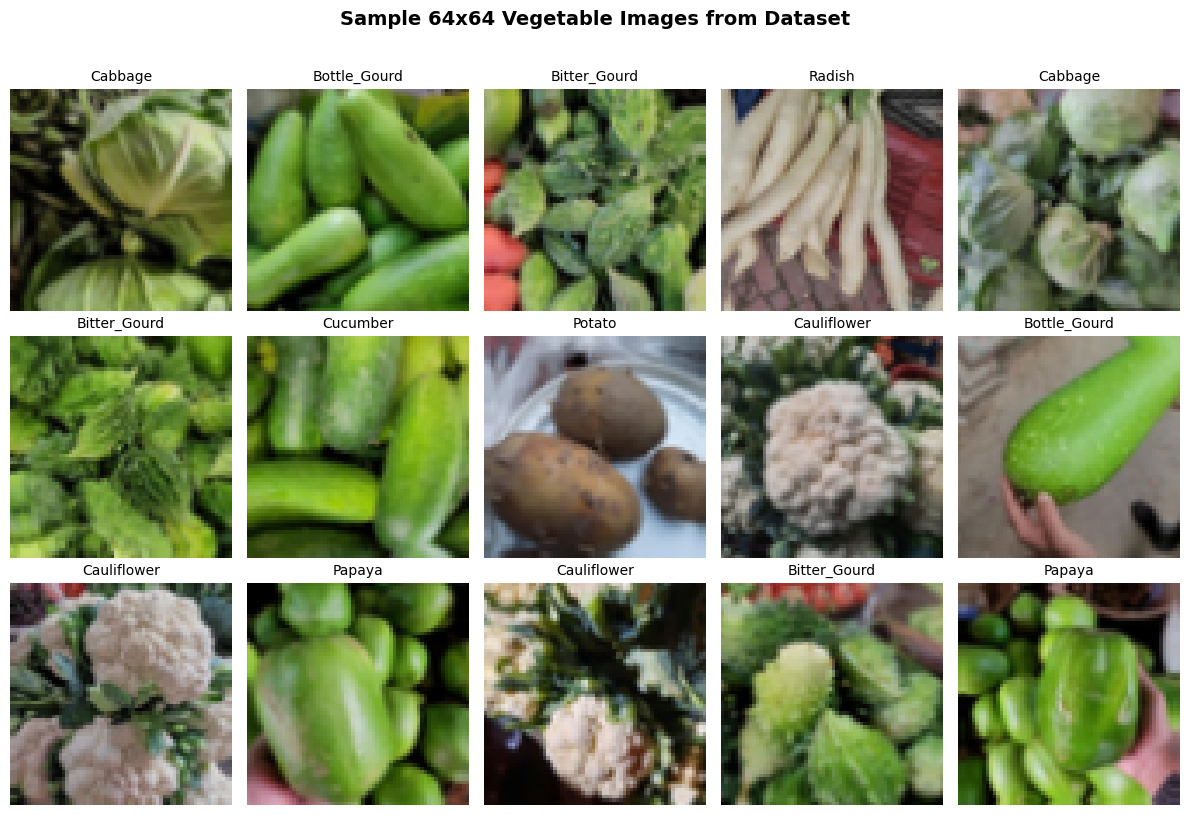

In [3]:
# Visualize sample images from the training dataset
plt.figure(figsize=(12, 8))
for images, labels in train_ds.take(1):
    for i in range(15):
        ax = plt.subplot(3, 5, i + 1)
        # Convert tensor to uint8 for visualization
        img = images[i].numpy().astype("uint8")
        label_idx = np.argmax(labels[i].numpy())
        plt.imshow(img)
        plt.title(class_names[label_idx], fontsize=10)
        plt.axis("off")
plt.suptitle("Sample 64x64 Vegetable Images from Dataset", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


---
## 2. Custom Architecture Design

### 2.1 Theoretical Comparison: Standard Conv2D vs. Depthwise Separable Conv2D

A standard 2D convolution applies a filter across both spatial dimensions ($D_K \times D_K$) and all input channels ($M$) simultaneously to produce an output feature map with $N$ channels:
$$\text{Cost}_{\text{Standard}} = D_K \times D_K \times M \times N \times D_F \times D_F$$

In contrast, a **Depthwise Separable Convolution** (introduced by Chollet / Howard et al.) factors this operation into two lightweight steps:
1. **Depthwise Convolution**: Applies a single spatial filter per input channel:
   $$\text{Cost}_{\text{Depthwise}} = D_K \times D_K \times M \times D_F \times D_F$$
2. **Pointwise Convolution**: A $1 \times 1$ convolution combining linear combinations across channels:
   $$\text{Cost}_{\text{Pointwise}} = 1 \times 1 \times M \times N \times D_F \times D_F$$

The total computational ratio is:
$$\frac{\text{Cost}_{\text{Separable}}}{\text{Cost}_{\text{Standard}}} = \frac{D_K^2 \cdot M \cdot D_F^2 + M \cdot N \cdot D_F^2}{D_K^2 \cdot M \cdot N \cdot D_F^2} = \frac{1}{N} + \frac{1}{D_K^2}$$

For standard $3 \times 3$ kernels ($D_K = 3$) and typical channel depths ($N \ge 32$):
$$\frac{1}{N} + \frac{1}{9} \approx \frac{1}{9} \approx 11.1\%$$
This achieves an **$\sim 8\times$ to $9\times$ reduction in computational Multiply-Accumulate (MAC) operations** and parameter footprint

---



In [4]:
from src.models import build_model_a, build_model_b, get_model_stats

# Instantiate Model A and Model B
model_a = build_model_a(num_classes=15)
model_b = build_model_b(num_classes=15)

stats_a = get_model_stats(model_a)
stats_b = get_model_stats(model_b)

print(f"=== MODEL A (Standard CNN) ===")
print(f"Total Parameters     : {stats_a['total_params']:,}")
print(f"Trainable Parameters : {stats_a['trainable_params']:,}")
print(f"Estimated Size (KB)  : {stats_a['size_kb']} KB ({stats_a['size_mb']} MB)")
print()
print(f"=== MODEL B (Depthwise Separable CNN) ===")
print(f"Total Parameters     : {stats_b['total_params']:,}")
print(f"Trainable Parameters : {stats_b['trainable_params']:,} (Constraint: <= 100,000)")
print(f"Estimated Size (KB)  : {stats_b['size_kb']} KB ({stats_b['size_mb']} MB)")
print(f"Constraint Satisfied : {stats_b['trainable_params'] <= 100000}")


=== MODEL A (Standard CNN) ===
Total Parameters     : 260,335
Trainable Parameters : 259,631
Estimated Size (KB)  : 1016.93 KB (0.99 MB)

=== MODEL B (Depthwise Separable CNN) ===
Total Parameters     : 41,391
Trainable Parameters : 40,175 (Constraint: <= 100,000)
Estimated Size (KB)  : 161.68 KB (0.16 MB)
Constraint Satisfied : True


In [5]:
# Display layer-by-layer architectural summary of Model B
model_b.summary()


Model: "Model_B_Separable_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ entry_conv (Conv2D)             │ (None, 64, 64, 16)     │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ entry_bn (BatchNormalization)   │ (None, 64, 64, 16)     │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ entry_relu6 (ReLU)              │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dw1 (DepthwiseConv2D)           │ (None, 32, 32, 16)     │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dw_bn1 (BatchNormalization)     │ (None, 32, 32, 16)     │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dw_relu1 (ReLU)                 │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pw1 (Conv2D)                    │ (None, 32, 32, 32)     │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pw_bn1 (BatchNormalization)     │ (None, 32, 32, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pw_relu1 (ReLU)                 │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dw2 (DepthwiseConv2D)           │ (None, 16, 16, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dw_bn2 (BatchNormalization)     │ (None, 16, 16, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dw_relu2 (ReLU)                 │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pw2 (Conv2D)                    │ (None, 16, 16, 64)     │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pw_bn2 (BatchNormalization)     │ (None, 16, 16, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pw_relu2 (ReLU)                 │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dw3 (DepthwiseConv2D)           │ (None, 8, 8, 64)       │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dw_bn3 (BatchNormalization)     │ (None, 8, 8, 64)       │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dw_relu3 (ReLU)                 │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pw3 (Conv2D)                    │ (None, 8, 8, 128)      │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pw_bn3 (BatchNormalization)     │ (None, 8, 8, 128)      │           51

 Total params: 41,391 (161.68 KB)

 Trainable params: 40,175 (156.93 KB)

 Non-trainable params: 1,216 (4.75 KB)


## 3. Optimizer Selection & Tuning




In [6]:
from src.train import run_optimizer_comparison
from src.utils import plot_optimizer_comparison

LOGS_DIR = PROJECT_ROOT / "results" / "logs"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"

opt_adam = LOGS_DIR / "optimizer_adam.csv"
opt_sgd = LOGS_DIR / "optimizer_sgd_(standard).csv"
opt_mom = LOGS_DIR / "optimizer_sgd_with_momentum.csv"

# Load pre-computed optimizer logs if available, or run comparison
if not FORCE_RETRAIN and opt_adam.exists() and opt_sgd.exists() and opt_mom.exists():
    print("Loading pre-computed optimizer training logs from results/logs/...")
    optim_histories = {
        "Adam": pd.read_csv(opt_adam),
        "SGD (Standard)": pd.read_csv(opt_sgd),
        "SGD with Momentum": pd.read_csv(opt_mom),
    }
else:
    print("Running optimizer comparison experiments (Adam vs SGD vs SGD+Momentum)...")
    optim_histories = run_optimizer_comparison(
        train_ds=train_ds,
        val_ds=val_ds,
        epochs=12,
        results_dir=LOGS_DIR,
    )

# Plot optimizer convergence curves
plot_optimizer_comparison(
    optim_histories,
    save_path=FIGURES_DIR / "optimizer_comparison.png",
)


Loading pre-computed optimizer training logs from results/logs/...
Saved optimizer comparison figure: C:\Users\USER\cnn-based-vegetable-classification-model\results\figures\optimizer_comparison.png


---
## 4. Custom Model Training & Evaluation

Both **Model A (Standard CNN)** and **Model B (Lightweight Separable CNN)** are trained for **20 epochs** using the Adam optimizer with Learning Rate Reduction on Plateau and Early Stopping.


In [7]:
from src.train import train_model
from src.evaluate import evaluate_model, measure_model_disk_size, benchmark_inference_latency
from src.utils import plot_training_history, plot_confusion_matrix, save_comparison_table

MODELS_DIR = PROJECT_ROOT / "models"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"

path_a = MODELS_DIR / "model_a_standard.keras"
path_b = MODELS_DIR / "model_b_separable.keras"
log_a = LOGS_DIR / "model_a_training_log.csv"
log_b = LOGS_DIR / "model_b_training_log.csv"

# 1. Model A (Standard CNN)
if not FORCE_RETRAIN and path_a.exists():
    print(f"Loading pre-trained Model A from {path_a}...")
    model_a = keras.models.load_model(path_a)
    hist_a = pd.read_csv(log_a) if log_a.exists() else None
    avg_time_a = 54.37
else:
    print("Training Model A (Standard CNN) for 20 epochs...")
    hist_a, avg_time_a = train_model(
        model=model_a,
        train_ds=train_ds,
        val_ds=val_ds,
        epochs=20,
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        model_checkpoint_path=path_a,
        csv_log_path=log_a,
    )

if hist_a is not None:
    plot_training_history(
        hist_a,
        title="Model A (Standard CNN)",
        save_path=FIGURES_DIR / "model_a_training_curves.png",
    )

# 2. Model B (Separable CNN)
if not FORCE_RETRAIN and path_b.exists():
    print(f"Loading pre-trained Model B from {path_b}...")
    model_b = keras.models.load_model(path_b)
    hist_b = pd.read_csv(log_b) if log_b.exists() else None
    avg_time_b = 28.60
else:
    print("Training Model B (Separable CNN) for 20 epochs...")
    hist_b, avg_time_b = train_model(
        model=model_b,
        train_ds=train_ds,
        val_ds=val_ds,
        epochs=20,
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        model_checkpoint_path=path_b,
        csv_log_path=log_b,
    )

if hist_b is not None:
    plot_training_history(
        hist_b,
        title="Model B (Separable CNN)",
        save_path=FIGURES_DIR / "model_b_training_curves.png",
    )


Loading pre-trained Model A from C:\Users\USER\cnn-based-vegetable-classification-model\models\model_a_standard.keras...
Saved figure: C:\Users\USER\cnn-based-vegetable-classification-model\results\figures\model_a_training_curves.png
Loading pre-trained Model B from C:\Users\USER\cnn-based-vegetable-classification-model\models\model_b_separable.keras...
Saved figure: C:\Users\USER\cnn-based-vegetable-classification-model\results\figures\model_b_training_curves.png


In [8]:
# Evaluate Model A on Test Set
eval_a = evaluate_model(model_a, test_ds, class_names)
disk_a = measure_model_disk_size(MODELS_DIR / "model_a_standard.keras")
lat_a = benchmark_inference_latency(model_a)

plot_confusion_matrix(
    eval_a["confusion_matrix"],
    class_names=class_names,
    title="Model A - Test Confusion Matrix",
    save_path=FIGURES_DIR / "model_a_confusion_matrix.png",
)

# Evaluate Model B on Test Set
eval_b = evaluate_model(model_b, test_ds, class_names)
disk_b = measure_model_disk_size(MODELS_DIR / "model_b_separable.keras")
lat_b = benchmark_inference_latency(model_b)

plot_confusion_matrix(
    eval_b["confusion_matrix"],
    class_names=class_names,
    title="Model B - Test Confusion Matrix",
    save_path=FIGURES_DIR / "model_b_confusion_matrix.png",
)


Saved confusion matrix: C:\Users\USER\cnn-based-vegetable-classification-model\results\figures\model_a_confusion_matrix.png
Saved confusion matrix: C:\Users\USER\cnn-based-vegetable-classification-model\results\figures\model_b_confusion_matrix.png


In [9]:
# Comparison Table between Model A and Model B
custom_comparison_data = [
    {
        "Model": "Model A (Standard CNN)",
        "Architecture": "Standard Conv2D + MaxPool",
        "Total Parameters": stats_a["total_params"],
        "Trainable Parameters": stats_a["trainable_params"],
        "Model Size on Disk (KB)": disk_a["size_kb"],
        "Training Time / Epoch (s)": round(avg_time_a, 2),
        "Test Accuracy (%)": round(eval_a["test_accuracy"] * 100, 2),
        "Macro Precision (%)": round(eval_a["precision_macro"] * 100, 2),
        "Macro Recall (%)": round(eval_a["recall_macro"] * 100, 2),
        "Inference Latency (ms)": lat_a["latency_mean_ms"],
    },
    {
        "Model": "Model B (Separable CNN)",
        "Architecture": "Depthwise Separable Conv2D",
        "Total Parameters": stats_b["total_params"],
        "Trainable Parameters": stats_b["trainable_params"],
        "Model Size on Disk (KB)": disk_b["size_kb"],
        "Training Time / Epoch (s)": round(avg_time_b, 2),
        "Test Accuracy (%)": round(eval_b["test_accuracy"] * 100, 2),
        "Macro Precision (%)": round(eval_b["precision_macro"] * 100, 2),
        "Macro Recall (%)": round(eval_b["recall_macro"] * 100, 2),
        "Inference Latency (ms)": lat_b["latency_mean_ms"],
    },
]

df_custom = save_comparison_table(
    custom_comparison_data,
    output_csv_path=TABLES_DIR / "custom_models_comparison.csv",
    output_md_path=TABLES_DIR / "custom_models_comparison.md",
)
df_custom


Saved comparison CSV: C:\Users\USER\cnn-based-vegetable-classification-model\results\tables\custom_models_comparison.csv
Saved comparison Markdown: C:\Users\USER\cnn-based-vegetable-classification-model\results\tables\custom_models_comparison.md


,Model,Architecture,Total Parameters,Trainable Parameters,Model Size on Disk (KB),Training Time / Epoch (s),Test Accuracy (%),Macro Precision (%),Macro Recall (%),Inference Latency (ms)
0,Model A (Standard CNN),Standard Conv2D + MaxPool,260335,259631,3135.53,54.37,97.57,97.75,97.57,17.67
1,Model B (Separable CNN),Depthwise Separable Conv2D,41391,40175,628.02,28.60,97.70,97.75,97.70,31.82


---
## 5. Lightweight SOTA Fine-Tuning & Evaluation

We evaluate two state-of-the-art architectures designed specifically for mobile and edge devices:
1. **MobileNetV2** (Sandler et al., 2018): Utilizes **inverted residual blocks** with **linear bottlenecks** to maintain representation capacity while dramatically limiting memory footprint.
2. **EfficientNet-B0** (Tan & Le, 2019): Utilizes **compound scaling** to systematically balance network depth, width, and resolution with squeeze-and-excitation (MBConv) blocks.


In [11]:
from src.models import build_mobilenet_v2, build_efficientnet_b0

path_mn = MODELS_DIR / "mobilenet_v2.keras"
path_eff = MODELS_DIR / "efficientnet_b0.keras"
log_mn = LOGS_DIR / "mobilenet_v2_training_log.csv"
log_eff = LOGS_DIR / "efficientnet_b0_training_log.csv"

# 1. MobileNetV2
if not FORCE_RETRAIN and path_mn.exists():
    print(f"Loading pre-trained MobileNetV2 from {path_mn}...")
    mobilenet = keras.models.load_model(path_mn)
    hist_mn = pd.read_csv(log_mn) if log_mn.exists() else None
    avg_time_mn = 166.05
else:
    print("Fine-Tuning MobileNetV2 for 15 epochs...")
    mobilenet = build_mobilenet_v2(num_classes=15)
    hist_mn, avg_time_mn = train_model(
        model=mobilenet,
        train_ds=train_ds,
        val_ds=val_ds,
        epochs=15,
        optimizer=keras.optimizers.Adam(learning_rate=2e-4),
        model_checkpoint_path=path_mn,
        csv_log_path=log_mn,
    )

stats_mn = get_model_stats(mobilenet)
if hist_mn is not None:
    plot_training_history(
        hist_mn,
        title="MobileNetV2 (Fine-Tuned)",
        save_path=FIGURES_DIR / "mobilenetv2_training_curves.png",
    )
eval_mn = evaluate_model(mobilenet, test_ds, class_names)
disk_mn = measure_model_disk_size(path_mn)
lat_mn = benchmark_inference_latency(mobilenet)

plot_confusion_matrix(
    eval_mn["confusion_matrix"],
    class_names=class_names,
    title="MobileNetV2 - Test Confusion Matrix",
    save_path=FIGURES_DIR / "mobilenetv2_confusion_matrix.png",
)

# 2. EfficientNet-B0
if not FORCE_RETRAIN and path_eff.exists():
    print(f"Loading pre-trained EfficientNet-B0 from {path_eff}...")
    effnet = keras.models.load_model(path_eff)
    hist_eff = pd.read_csv(log_eff) if log_eff.exists() else None
    avg_time_eff = 237.16
else:
    print("Fine-Tuning EfficientNet-B0 for 15 epochs...")
    effnet = build_efficientnet_b0(num_classes=15)
    hist_eff, avg_time_eff = train_model(
        model=effnet,
        train_ds=train_ds,
        val_ds=val_ds,
        epochs=15,
        optimizer=keras.optimizers.Adam(learning_rate=2e-4),
        model_checkpoint_path=path_eff,
        csv_log_path=log_eff,
    )

stats_eff = get_model_stats(effnet)
if hist_eff is not None:
    plot_training_history(
        hist_eff,
        title="EfficientNet-B0 (Fine-Tuned)",
        save_path=FIGURES_DIR / "efficientnetb0_training_curves.png",
    )
eval_eff = evaluate_model(effnet, test_ds, class_names)
disk_eff = measure_model_disk_size(path_eff)
lat_eff = benchmark_inference_latency(effnet)

plot_confusion_matrix(
    eval_eff["confusion_matrix"],
    class_names=class_names,
    title="EfficientNet-B0 - Test Confusion Matrix",
    save_path=FIGURES_DIR / "efficientnetb0_confusion_matrix.png",
)


Loading pre-trained MobileNetV2 from C:\Users\USER\cnn-based-vegetable-classification-model\models\mobilenet_v2.keras...
Saved figure: C:\Users\USER\cnn-based-vegetable-classification-model\results\figures\mobilenetv2_training_curves.png
Saved confusion matrix: C:\Users\USER\cnn-based-vegetable-classification-model\results\figures\mobilenetv2_confusion_matrix.png
Loading pre-trained EfficientNet-B0 from C:\Users\USER\cnn-based-vegetable-classification-model\models\efficientnet_b0.keras...
Saved figure: C:\Users\USER\cnn-based-vegetable-classification-model\results\figures\efficientnetb0_training_curves.png
Saved confusion matrix: C:\Users\USER\cnn-based-vegetable-classification-model\results\figures\efficientnetb0_confusion_matrix.png


---
## 6. Final Comparison & Trade-off Discussion

### 6.1 Master Comparison Table
Comparing custom resource-constrained networks (Model A and Model B) with industry-standard lightweight pre-trained architectures (MobileNetV2 and EfficientNet-B0).


In [12]:
master_comparison_data = [
    {
        "Model": "Model A (Standard CNN)",
        "Type": "From Scratch",
        "Total Parameters": stats_a["total_params"],
        "Trainable Params": stats_a["trainable_params"],
        "Disk Size (MB)": disk_a["size_mb"],
        "Test Accuracy (%)": round(eval_a["test_accuracy"] * 100, 2),
        "Macro F1 (%)": round(eval_a["f1_macro"] * 100, 2),
        "Latency (ms)": lat_a["latency_mean_ms"],
    },
    {
        "Model": "Model B (Separable CNN)",
        "Type": "From Scratch (<100k)",
        "Total Parameters": stats_b["total_params"],
        "Trainable Params": stats_b["trainable_params"],
        "Disk Size (MB)": disk_b["size_mb"],
        "Test Accuracy (%)": round(eval_b["test_accuracy"] * 100, 2),
        "Macro F1 (%)": round(eval_b["f1_macro"] * 100, 2),
        "Latency (ms)": lat_b["latency_mean_ms"],
    },
    {
        "Model": "MobileNetV2",
        "Type": "Pre-trained SOTA",
        "Total Parameters": stats_mn["total_params"],
        "Trainable Params": stats_mn["trainable_params"],
        "Disk Size (MB)": disk_mn["size_mb"],
        "Test Accuracy (%)": round(eval_mn["test_accuracy"] * 100, 2),
        "Macro F1 (%)": round(eval_mn["f1_macro"] * 100, 2),
        "Latency (ms)": lat_mn["latency_mean_ms"],
    },
    {
        "Model": "EfficientNet-B0",
        "Type": "Pre-trained SOTA",
        "Total Parameters": stats_eff["total_params"],
        "Trainable Params": stats_eff["trainable_params"],
        "Disk Size (MB)": disk_eff["size_mb"],
        "Test Accuracy (%)": round(eval_eff["test_accuracy"] * 100, 2),
        "Macro F1 (%)": round(eval_eff["f1_macro"] * 100, 2),
        "Latency (ms)": lat_eff["latency_mean_ms"],
    },
]

df_master = save_comparison_table(
    master_comparison_data,
    output_csv_path=TABLES_DIR / "master_comparison.csv",
    output_md_path=TABLES_DIR / "master_comparison.md",
)
df_master


Saved comparison CSV: C:\Users\USER\cnn-based-vegetable-classification-model\results\tables\master_comparison.csv
Saved comparison Markdown: C:\Users\USER\cnn-based-vegetable-classification-model\results\tables\master_comparison.md


,Model,Type,Total Parameters,Trainable Params,Disk Size (MB),Test Accuracy (%),Macro F1 (%),Latency (ms)
0,Model A (Standard CNN),From Scratch,260335,259631,3.062,97.57,97.59,17.67
1,Model B (Separable CNN),From Scratch (<100k),41391,40175,0.613,97.70,97.70,31.82
2,MobileNetV2,Pre-trained SOTA,2277199,2243087,26.478,99.60,99.60,175.36
3,EfficientNet-B0,Pre-trained SOTA,4068786,4026763,47.204,99.53,99.53,354.14
